# 18 全館空調の保存入力を再計算

## 元の計算と今回の範囲
261112_全館空調_湿度3方式_C値6条件比較の計算で保存された年間入力を使います。25節点、405換気枝、183面、空調1台を含みます。元入力は2026年の8760時間です。

保存元は `20261112_latent3_c6_round6_data.zip` の元入力です。今回Driveから取得した原典とローカル保管原典がSHA-256で一致することを確認しています。気象等から入力を再生成したものではありません。

今回確認したのは **1月15日と8月1日の各24時間、隙間倍率1、rh95** です。期間を切り出す際、すべての8760要素の時系列を同じ位置で切り出し、元の初期値から開始します。したがって通年計算の当日を切り出した結果とは異なります。比較研究には助走期間を設けて評価区間を分けます。

engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。原典の年間結果との一致や18条件の年間収束は今回未検証です。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力は同じフォルダのhouse_annual_input.json.gzに保存しています。気象・風圧・スケジュールを含むため、元CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/18/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "18"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力ファイルの配置
同じフォルダの `house_annual_input.json.gz` を、このノートから読める場所へ置きます。ColabではDriveをマウントして、DATA_DIRを保存フォルダの絶対パスに変更します。入力のSHA-256を毎回検査します。

In [ ]:
# GitHub/Colabでも、同じフォルダの入力を優先して使う。
# 見つからない場合は公開リポジトリの固定commitから取得し、保存前にSHA-256を確認する。
import hashlib
from urllib.request import urlopen

input_file = DATA_DIR / "house_annual_input.json.gz"
INPUT_URL = "https://raw.githubusercontent.com/iguchi-lab/vtsimnx/577cad46e37fe9042582425699ee4205918e8193/tutorials/house_annual_input.json.gz"
EXPECTED_SHA256 = "f983ca142ad7acb1e13008ad8dd2e96be6429651250d38d03fb2598cd6a1b179"
if not input_file.exists():
    with urlopen(INPUT_URL, timeout=120) as response:
        payload = response.read(32 * 1024 * 1024)
    if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256:
        raise ValueError("取得した入力のSHA-256が一致しません。入力は保存していません。")
    input_file.write_bytes(payload)
if hashlib.sha256(input_file.read_bytes()).hexdigest() != EXPECTED_SHA256:
    raise ValueError("同梱入力のSHA-256が一致しません。元の入力ファイルを配置してください。")


In [4]:
"""Use the saved original annual model; select an explicit time window and gap/latent variant."""
from pathlib import Path
from datetime import datetime
import gzip
import hashlib
import json

INPUT_SHA256 = 'f983ca142ad7acb1e13008ad8dd2e96be6429651250d38d03fb2598cd6a1b179'
OUTSIDE = {'東', '西', '南', '北'}


def is_exterior_gap(branch):
    ends = [s.strip() for s in branch.get('key', '').split('||', 1)[0].split('->')]
    return (branch.get('type') == 'gap' and len(ends) == 2
            and ((ends[0] in OUTSIDE) != (ends[1] in OUTSIDE)))


def make_house(start='2026-01-15 00:00:00', hours=24, method='rh95', multiplier=1.0):
    """Slice every annual time series consistently. A short run starts from original initial states."""
    path = DATA_DIR / 'house_annual_input.json.gz'
    payload = path.read_bytes()
    if hashlib.sha256(payload).hexdigest() != INPUT_SHA256:
        raise ValueError('The saved annual input hash has changed')
    config = json.loads(gzip.decompress(payload))
    index = config['simulation']['index']
    dates = [datetime.fromisoformat(s) for s in index]
    offset = dates.index(datetime.fromisoformat(start))
    if not isinstance(hours, int) or hours < 2 or offset + hours > len(index):
        raise ValueError('Choose at least two hours within the saved year')
    if method not in ('rh95', 'bf', 'coil_aoaf') or multiplier < 0:
        raise ValueError('Unsupported latent method or negative gap multiplier')
    assert all((b-a).total_seconds() == 3600 for a,b in zip(dates,dates[1:]))
    n = len(index)
    def window(value):
        if isinstance(value, dict):
            return {key: window(item) for key,item in value.items()}
        if isinstance(value, list):
            return value[offset:offset+hours] if len(value) == n else [window(item) for item in value]
        return value
    config = window(config)
    config['simulation']['index'] = {'start': dates[offset].isoformat(),
        'end': dates[offset+hours-1].isoformat(), 'length': hours, 'timestep': 3600}
    branches = config['ventilation_branches']
    assert any(is_exterior_gap(b) for b in branches)
    config['ventilation_branches'] = [b for b in branches if multiplier or not is_exterior_gap(b)]
    for branch in config['ventilation_branches']:
        if is_exterior_gap(branch):
            branch['a'] *= multiplier
    for ac in config['aircon']:
        ac.pop('pre_rh', None)
        ac['control_mode'] = 'temperature_priority'
        ac['ac_spec'].update(latent_method=method, bf=0.2, Af=0.133, Ao=4.84)
    return config


## 短い期間でモデルを確認
室名、接続、運転条件は保存入力を引き継ぎます。潜熱方式はrh95、BF=0.2、Af=0.133 m²、Ao=4.84 m²を明示します。Af・Aoは比較用の設定値であり、実機同定値ではありません。

,外部,LD,和室,2階ホール,AC出口
time,,,,,
2026-01-15 00:00:00,4.9,20.0,19.906784,19.641647,32.502647
2026-01-15 01:00:00,4.3,20.0,19.774187,19.345079,32.208988
2026-01-15 02:00:00,4.3,20.0,19.646896,19.098045,31.957514
2026-01-15 03:00:00,4.5,20.0,19.503807,18.922369,31.763111
2026-01-15 04:00:00,4.1,20.0,19.413589,18.772728,31.604687


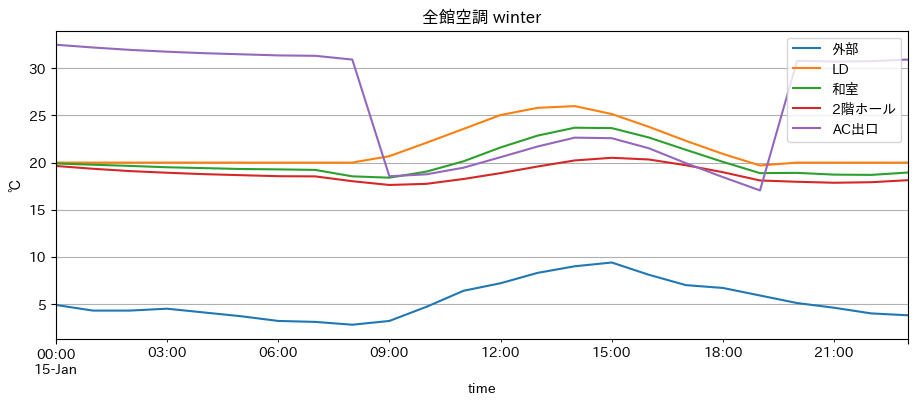

,外部,LD,和室,2階ホール,AC出口
time,,,,,
2026-08-01 00:00:00,26.9,20.737343,20.524134,20.404182,20.855566
2026-08-01 01:00:00,26.4,21.255795,20.950972,20.883690,21.418728
2026-08-01 02:00:00,26.1,21.670904,21.329451,21.373615,21.891579
2026-08-01 03:00:00,25.6,21.991499,21.649824,21.822302,22.276787
2026-08-01 04:00:00,25.5,22.275303,21.938833,22.229012,22.648232


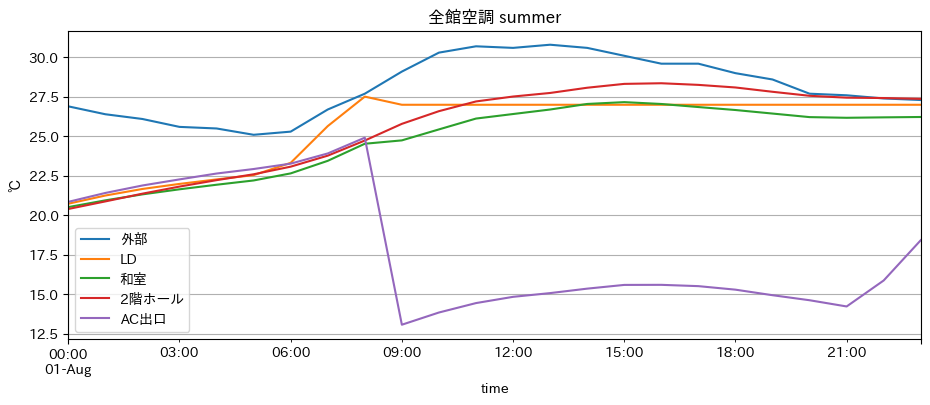

In [5]:
configs = {"winter":make_house("2026-01-15 00:00:00"),
           "summer":make_house("2026-08-01 00:00:00")}
results = {}
for name,config in configs.items():
    results[name] = vt.run_calc(BASE_URL,config,api_key=API_KEY,as_result=True,raise_on_error=True,
        timeout=3600, request_output_path=OUTPUT / ("house_"+name+"_request.json"))
    frame = results[name].get_series_df("thermal_temperature",raise_on_error=True)
    display(frame[[c for c in ["外部","LD","和室","2階ホール","AC出口"] if c in frame]].head())
    frame.to_csv(OUTPUT / ("house_"+name+"_temperature.csv"),encoding="utf-8-sig")

    assert np.isfinite(frame.to_numpy()).all()
    columns = [c for c in ["外部", "LD", "和室", "2階ホール", "AC出口"] if c in frame]
    ax = frame[columns].plot(figsize=(11,4),grid=True,title="全館空調 " + name,ylabel="℃")
    ax.figure.savefig(OUTPUT / ("house_"+name+"_temperature.png"),dpi=140,bbox_inches="tight")
    plt.show()


## 年間18条件へ広げる
`make_house("2026-01-01 00:00:00", hours=8760, method=method, multiplier=multiplier)` で、原典と同じ8760時間の入力を作れます。

- method: rh95 / bf / coil_aoaf
- multiplier: 0 / 0.5 / 1 / 2 / 4 / 8

18組を一つずつ実行して要求JSONと結果を保存します。まず1組を完了させ、収束ログ・未達量・出力列を確認してから組合せを増やします。このノートの既定セルでは年間18条件を自動投入しません。

倍率0は外皮隙間の枝を削除します。外気とつながる隙間だけを変え、室間隙間とその他の条件を保持します。倍率はC値そのものではなく、C値への換算条件は元ノートを参照してください。空調の室温制御点・吸込・吹出は異なる節点です。

## 結果を評価する
室温・絶対湿度・RH、空調顕熱・潜熱・電力、未達量、外気流入量と圧力を比較します。冷暖房の符号、電力の単位、時間積分の刻みをschemaと突き合わせます。短期間の積算値を年間値と呼びません。